# Лабораторная работа №2. Логистическая и линейная регрессия

**Цель:** провести исследование линейных моделей — логистической регрессии для классификации (Dota 2) и линейной регрессии для регрессии (шахматный эндшпиль KRKPA7): бейзлайн `sklearn`, улучшение бейзлайна через проверку гипотез, собственная реализация и сравнение (пункты 2–4 ЛР №1).

Наборы данных, постановка задач и обоснование метрик подробно описаны в разделе 1 ЛР №1 (`lab1_knn.ipynb`). Метрики: для классификации — **ROC-AUC** (основная), accuracy, F1; для регрессии — **R²** (основная), RMSE, MAE.

## 0. Подготовка окружения

Импортируем библиотеки и общий пакет `mllab` из корня репозитория. В `mllab` лежат:
загрузчики данных (`mllab.data`), генераторы признаков (`mllab.features`), функции подсчёта метрик и журнал результатов (`mllab.metrics`), а также собственные реализации алгоритмов (`mllab.knn`, `mllab.linear`, `mllab.tree`, `mllab.forest`, `mllab.boosting`).
Предупреждения отключаем, чтобы не засорять вывод; для `Pipeline` включаем дисковый кэш (`.cache/`), чтобы тяжёлые преобразования признаков не пересчитывались в каждом прогоне кросс-валидации.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Code, display
from joblib import Memory
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

import mllab
from mllab.data import RANDOM_STATE, load_chess, load_dota
from mllab.features import ChessFeatures, DotaFeatures
from mllab.metrics import ResultsLog, compare_cv, cv_report, evaluate

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)
memory = Memory(ROOT / ".cache", verbose=0)

Загружаем данные (подробное описание и обоснование выбора — в разделе 1 ЛР №1):
* **классификация** — *Dota 2 Games Results*: используем официальное разбиение UCI на train (92 650 матчей) и test (10 294 матча); целевая переменная `1` — победила команда 1;
* **регрессия** — *Chess KR vs KP (KRKPA7)*: стратифицированное разбиение 80/20 (`random_state=42`); целевая переменная `1.0` — белые выигрывают, `0.0` — нет; модель предсказывает непрерывную «оценку позиции».

Гиперпараметры подбираем только на train через 5-кратную кросс-валидацию (`StratifiedKFold` для классификации, `KFold` для регрессии); test используется только для финальной оценки.

In [2]:
X_cls_train, X_cls_test, y_cls_train, y_cls_test = load_dota()
X_reg_train, X_reg_test, y_reg_train, y_reg_test = load_chess()

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Классификация (Dota 2):", X_cls_train.shape, X_cls_test.shape)
print("Регрессия (шахматы KRKPA7):", X_reg_train.shape, X_reg_test.shape)

log = ResultsLog(lab=2, algorithm="Linear")

Классификация (Dota 2): (92650, 116) (10294, 116)
Регрессия (шахматы KRKPA7): (2556, 36) (640, 36)


## 2. Создание бейзлайна и оценка качества

Бейзлайн — модели `sklearn` с параметрами по умолчанию:
* классификация — `LogisticRegression` (L2-регуляризация, `C=1`, решатель `lbfgs`; `max_iter` увеличен до 1000, иначе на немасштабированных данных решатель не сходится) на исходных 116 признаках;
* регрессия — `LinearRegression` (метод наименьших квадратов) поверх кодирования `ChessFeatures`.

In [3]:
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge

baseline_cls = LogisticRegression(max_iter=1000)
baseline_reg = make_pipeline(ChessFeatures(), LinearRegression())

log.add("classification", "sklearn baseline",
        evaluate(baseline_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn baseline",
        evaluate(baseline_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6342,0.5979,0.6399,29.5438,0.0419


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6420,0.2989,0.2583,0.1220,0.0129


Посмотрим на распределение предсказаний линейной регрессии: для цели 0/1 линейная модель не ограничена отрезком [0, 1].

Предсказаний < 0: 0.128, > 1: 0.092


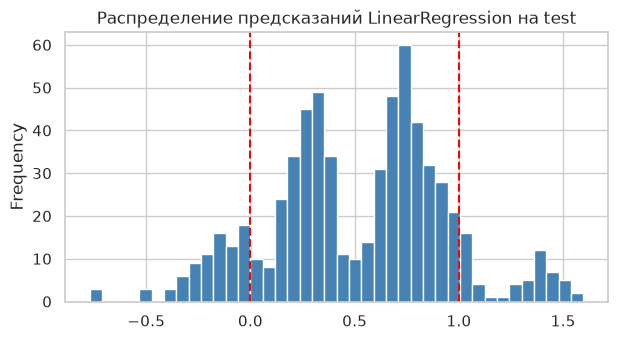

In [4]:
baseline_pred = baseline_reg.predict(X_reg_test)
print(f"Предсказаний < 0: {np.mean(baseline_pred < 0):.3f}, > 1: {np.mean(baseline_pred > 1):.3f}")
ax = pd.Series(baseline_pred).plot.hist(bins=40, figsize=(7, 3.5), color="steelblue",
                                       title="Распределение предсказаний LinearRegression на test")
ax.axvline(0, color="red", ls="--")
ax.axvline(1, color="red", ls="--")
plt.show()

<!-- lab2_baseline -->
**Вывод по бейзлайну.**
* *Классификация:* логистическая регрессия «из коробки» даёт ROC-AUC = 0.634 и accuracy = 0.598 — заметно лучше KNN-бейзлайна из ЛР №1 (0.53): аддитивная модель «сила команды = сумма вкладов героев» хорошо подходит к данным. Но обучение заняло ≈30 с: на немасштабированных признаках (`cluster_id` ~ 100–260) решатель `lbfgs` сходится очень медленно.
* *Регрессия:* МНК объясняет только 64 % дисперсии (R² = 0.642, MAE = 0.258). Правила эндшпиля — логические комбинации признаков, а модель аддитивна. Кроме того, 12.8 % предсказаний меньше 0 и 9.2 % больше 1 — для оценки шансов это заведомо бессмысленные значения.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация (Dota 2):**
* **H1. Стандартизация признаков.** `cluster_id` имеет масштаб в сотни раз больше остальных признаков: это замедляет сходимость оптимизатора и делает L2-штраф неравномерным по признакам.
* **H2. Обработка мета-признаков и представление героев.** Линейная модель не может использовать категориальный код сервера как число. Проверим удаление мета-признаков, one-hot кодирование серверов и регионов (`cluster_id // 10`), а также раздельные индикаторы героев для команд 1 и 2 вместо кодирования ±1.
* **H3. Признаки синергии и контрпиков.** Линейная модель по индикаторам героев учитывает только «силу» отдельных героев и не видит взаимодействий. Добавим агрегированные статистики пар героев: синергию внутри команды и контрпики между командами (out-of-fold, без утечки).
* **H4. Сила регуляризации** (`C`) и тип штрафа (L2 / L1) на кросс-валидации.

**Регрессия (шахматы):**
* **H1. Ограничение предсказаний отрезком [0, 1].** Цель — оценка шансов, поэтому выход за границы — заведомая ошибка; обрезка (`ClippedRegressor`) может только уменьшить ошибку.
* **H2. Попарные взаимодействия признаков.** Исход эндшпиля определяется логическими *комбинациями* условий («король отрезан **и** ладья под ударом»), а линейная модель аддитивна. Добавим все попарные произведения бинарных признаков (логическое «И») — 38 + 703 признака.
* **H3. Регуляризация.** После добавления взаимодействий признаков становится много (741 на 2 556 объектов) — нужна L2 (`Ridge`) или L1 (`Lasso`) регуляризация; подбираем силу на кросс-валидации.

### 3.2. Проверка гипотез для классификации

**H1.** Сравниваем логистическую регрессию на сырых и стандартизованных признаках: ROC-AUC на 5-кратной кросс-валидации и среднее время обучения.

In [5]:
h1_cls = compare_cv({
    "сырые признаки": LogisticRegression(max_iter=1000),
    "StandardScaler": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h1_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
сырые признаки,0.6353,0.0037,0.6387,10.4147
StandardScaler,0.6353,0.0037,0.6387,0.3919


<!-- lab2_h1_cls -->
**H1 подтверждена частично.** Качество не изменилось (ROC-AUC = 0.6353 в обоих случаях — оптимум логистической регрессии не зависит от масштаба признаков при слабой регуляризации), но обучение ускорилось в ≈27 раз (10.4 с → 0.39 с). Стандартизацию оставляем: она нужна для сходимости и для того, чтобы L2-штраф одинаково действовал на все признаки.

**H2.** Сравниваем варианты обработки мета-признаков и представления героев (все — со стандартизацией).

In [6]:
def logreg_on(features):
    return make_pipeline(features, StandardScaler(), LogisticRegression(max_iter=1000))

h2_cls = compare_cv({
    "мета как числа": logreg_on(DotaFeatures(meta="raw")),
    "без мета-признаков": logreg_on(DotaFeatures(meta="drop", drop_constant=True)),
    "one-hot серверов": logreg_on(DotaFeatures(meta="onehot", drop_constant=True)),
    "one-hot регионов": logreg_on(DotaFeatures(meta="region", drop_constant=True)),
    "раздельные индикаторы команд": logreg_on(DotaFeatures(meta="drop", heroes="split", drop_constant=True)),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h2_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
мета как числа,0.6353,0.0037,0.6387,0.3440
без мета-признаков,0.6354,0.0037,0.6387,0.3415
one-hot серверов,0.6353,0.0037,0.6403,0.7681
one-hot регионов,0.6357,0.0039,0.6399,0.5898
раздельные индикаторы команд,0.6341,0.0037,0.6410,0.8495


<!-- lab2_h2_cls -->
**H2 не подтверждена.** Все варианты обработки мета-признаков дают ROC-AUC 0.6353–0.6357, различия на порядок меньше стандартного отклонения по фолдам (0.0037): сервер/регион и режим игры практически не влияют на исход матча. Раздельные индикаторы для команд немного хуже (0.6341) — удвоение числа признаков без нового сигнала (кодирование ±1 уже правильно отражает симметрию: герой в команде 1 увеличивает шансы команды 1 так же, как в команде 2 — шансы команды 2). Для простоты модели мета-признаки удаляем.

**H3.** Добавляем признаки синергии и контрпиков к индикаторам героев (с регионами и без).

In [7]:
h3_cls = compare_cv({
    "индикаторы героев": logreg_on(DotaFeatures(meta="drop", drop_constant=True)),
    "+ win rate команд": logreg_on(DotaFeatures(meta="drop", drop_constant=True, winrate=True)),
    "+ синергия и контрпики": logreg_on(DotaFeatures(meta="drop", drop_constant=True, synergy=True)),
    "+ синергия и контрпики + регионы": logreg_on(DotaFeatures(meta="region", drop_constant=True, synergy=True)),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h3_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
индикаторы героев,0.6354,0.0037,0.6387,0.4394
+ win rate команд,0.6354,0.0037,0.6387,7.1317
+ синергия и контрпики,0.6389,0.0033,0.6794,6.9184
+ синергия и контрпики + регионы,0.6391,0.0035,0.6798,7.5020


<!-- lab2_h3_cls -->
**H3 подтверждена.** Win rate команд сам по себе ничего не добавляет (0.6354): линейная модель по индикаторам героев и так выучивает «силу» каждого героя в виде коэффициентов. А вот признаки **синергии и контрпиков** несут информацию о *парах* героев, недоступную линейной модели, — ROC-AUC вырос до 0.6389 (+0.0035, это заметно больше разброса 0.0033). Регионы добавляют лишь 0.0002 — не используем.

**H4.** Подбираем силу регуляризации `C` и тип штрафа. В `sklearn ≥ 1.8` тип штрафа задаётся параметром `l1_ratio` (0 — L2, 1 — L1); для L1 используется решатель `saga`.

In [8]:
pipe_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", drop_constant=True, synergy=True)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
], memory=memory)
search_cls = GridSearchCV(pipe_cls, [
    {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1.0], "model__l1_ratio": [0.0]},
    {"model__C": [0.003, 0.01, 0.1], "model__l1_ratio": [1.0], "model__solver": ["saga"]},
], cv=cv_cls, scoring="roc_auc", n_jobs=5).fit(X_cls_train, y_cls_train)
print("Лучшие параметры:", search_cls.best_params_)
cv_report(search_cls)

Лучшие параметры: {'model__C': 1.0, 'model__l1_ratio': 0.0}


,model__C,model__l1_ratio,model__solver,mean_test_score,std_test_score,rank_test_score
0,1.0000,0.0000,NaN,0.6389,0.0033,1
1,0.1000,0.0000,NaN,0.6389,0.0033,2
2,0.0300,0.0000,NaN,0.6389,0.0033,3
3,0.1000,1.0000,saga,0.6389,0.0033,4
4,0.0100,0.0000,NaN,0.6389,0.0033,5
5,0.0030,0.0000,NaN,0.6388,0.0033,6
6,0.0010,0.0000,NaN,0.6388,0.0034,7
7,0.0100,1.0000,saga,0.6385,0.0037,8
8,0.0030,1.0000,saga,0.6378,0.0039,9


<!-- lab2_h4_cls -->
**H4: регуляризация почти не влияет.** При C ≥ 0.003 ROC-AUC на CV стабильно 0.6388–0.6389; L1-штраф не лучше L2 и при сильной регуляризации (C = 0.003) хуже. Это ожидаемо: 92 тыс. объектов на 118 признаков — переобучаться модели почти не на чем. Лучший вариант — L2 с `C = 1` (по умолчанию).

Посмотрим на коэффициенты лучшей модели: какие признаки сильнее всего влияют на вероятность победы команды 1.

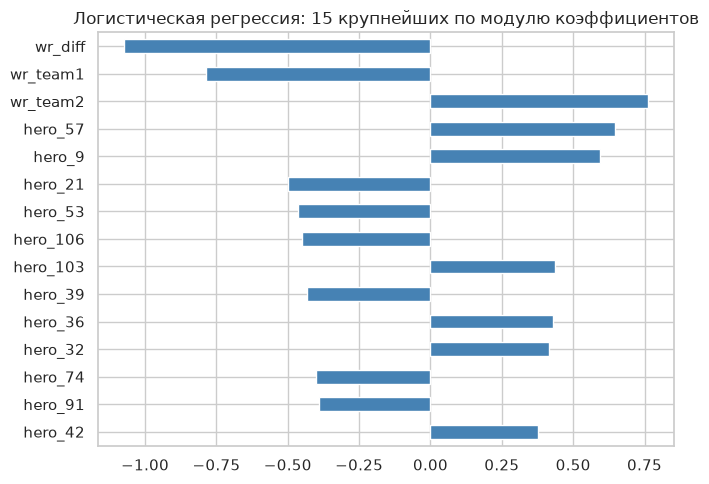

In [9]:
best_pipe = search_cls.best_estimator_
coefs = pd.Series(best_pipe.named_steps["model"].coef_[0],
                  index=best_pipe.named_steps["features"].get_feature_names_out())
coefs.reindex(coefs.abs().sort_values().index).tail(15).plot.barh(
    figsize=(7, 5), color="steelblue", title="Логистическая регрессия: 15 крупнейших по модулю коэффициентов")
plt.tight_layout()

### 3.3. Проверка гипотез для регрессии

**H1 и H2.** Сравниваем на кросс-валидации обычную линейную регрессию, её вариант с обрезкой предсказаний и модель с попарными взаимодействиями.

In [10]:
from mllab.linear import ClippedRegressor

h12_reg = compare_cv({
    "МНК (бейзлайн)": make_pipeline(ChessFeatures(), LinearRegression()),
    "МНК + обрезка [0, 1]": make_pipeline(ChessFeatures(), ClippedRegressor(LinearRegression())),
    "МНК + взаимодействия": make_pipeline(ChessFeatures(interactions=True), LinearRegression()),
    "МНК + взаимодействия + обрезка": make_pipeline(ChessFeatures(interactions=True),
                                                    ClippedRegressor(LinearRegression())),
}, X_reg_train, y_reg_train, cv_reg, "r2")
h12_reg

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
МНК (бейзлайн),0.6247,0.0208,0.6393,0.0472
"МНК + обрезка [0, 1]",0.6823,0.0213,0.6947,0.0232
МНК + взаимодействия,0.8562,0.0115,0.9325,0.2724
МНК + взаимодействия + обрезка,0.9021,0.0085,0.9501,0.4535


<!-- lab2_h12_reg -->
**H1 и H2 подтверждены.**
* Обрезка предсказаний в [0, 1] повышает R² на CV с 0.625 до 0.682 — бесплатное улучшение, т. к. цель гарантированно лежит в этом отрезке.
* Попарные взаимодействия дают главный прирост: R² 0.856, а вместе с обрезкой — 0.902. Логическое «И» двух признаков позволяет линейной модели описывать условия вида «A и B одновременно». При этом разрыв train/CV (0.950 / 0.902) говорит о переобучении на 741 признаке — нужна регуляризация.

**H3.** Сравниваем L2 (`Ridge`) и L1 (`Lasso`) регуляризацию разной силы для модели со взаимодействиями (с обрезкой предсказаний).

In [11]:
candidates = {f"Ridge alpha={a}": make_pipeline(ChessFeatures(interactions=True), ClippedRegressor(Ridge(alpha=a)))
              for a in [0.1, 1.0, 10.0, 100.0]}
candidates |= {f"Lasso alpha={a}": make_pipeline(ChessFeatures(interactions=True),
                                                 ClippedRegressor(Lasso(alpha=a, max_iter=5000)))
               for a in [0.0001, 0.001]}
h3_reg = compare_cv(candidates, X_reg_train, y_reg_train, cv_reg, "r2")
h3_reg

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
Ridge alpha=0.1,0.9073,0.0072,0.9493,0.1599
Ridge alpha=1.0,0.9123,0.0073,0.9444,0.1401
Ridge alpha=10.0,0.8932,0.0092,0.9187,0.1413
Ridge alpha=100.0,0.8085,0.0163,0.8290,0.1372
Lasso alpha=0.0001,0.9143,0.0079,0.9409,2.2818
Lasso alpha=0.001,0.8771,0.0127,0.8907,0.4776


<!-- lab2_h3_reg -->
**H3 подтверждена.** Умеренная регуляризация улучшает модель со взаимодействиями: Ridge с `alpha = 1` — R² = 0.912 (против 0.902 без регуляризации), слишком сильная (`alpha = 100`) — недообучение (0.809). Lasso с `alpha = 1e-4` даёт сопоставимый результат (0.914, разница меньше стандартного отклонения 0.008), но обучается в 16 раз дольше — выбираем Ridge (к тому же у него есть точное аналитическое решение).

Уточняем силу L2-регуляризации поиском по сетке.

In [12]:
pipe_reg = Pipeline([
    ("features", ChessFeatures(interactions=True)),
    ("model", ClippedRegressor(Ridge())),
])
search_reg = GridSearchCV(pipe_reg, {"model__estimator__alpha": [0.3, 0.5, 1.0, 2.0, 3.0, 5.0]},
                          cv=cv_reg, scoring="r2", n_jobs=-1).fit(X_reg_train, y_reg_train)
print("Лучшие параметры:", search_reg.best_params_)
cv_report(search_reg)

Лучшие параметры: {'model__estimator__alpha': 1.0}


,model__estimator__alpha,mean_test_score,std_test_score,rank_test_score
0,1.0000,0.9123,0.0073,1
1,0.5000,0.9119,0.0071,2
2,0.3000,0.9107,0.0070,3
3,2.0000,0.9106,0.0075,4
4,3.0000,0.9082,0.0077,5
5,5.0000,0.9034,0.0081,6


<!-- lab2_h3b_reg -->
**Итог подбора:** оптимум по сетке — `alpha = 1.0` (R² на CV = 0.912), качество слабо зависит от `alpha` в диапазоне 0.3–3.

### 3.4. Улучшенный бейзлайн

* **классификация** — индикаторы героев без мета-признаков + синергия и контрпики → `StandardScaler` → `LogisticRegression` с подобранными `C` и штрафом;
* **регрессия** — бинарные признаки + все попарные взаимодействия → `Ridge` с подобранным `alpha` → обрезка предсказаний в [0, 1].

In [13]:
from sklearn.base import clone

improved_cls = clone(search_cls.best_estimator_)
improved_reg = clone(search_reg.best_estimator_)

log.add("classification", "sklearn improved",
        evaluate(improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn improved",
        evaluate(improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6342,0.5979,0.6399,29.5438,0.0419
sklearn improved,0.6395,0.5988,0.6392,1.3509,0.1814


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6420,0.2989,0.2583,0.1220,0.0129
sklearn improved,0.9206,0.1407,0.0816,0.3741,0.0445


<!-- lab2_improved -->
**Сравнение улучшенного бейзлайна с бейзлайном (test).**
* *Классификация:* ROC-AUC 0.6342 → **0.6395** (+0.005), accuracy 0.598 → 0.599, F1 практически без изменений; время обучения сократилось с 29.5 с до 1.4 с. Прирост скромный — потолок задачи определяется тем, что исход матча Dota 2 лишь частично определяется драфтом.
* *Регрессия:* R² 0.642 → **0.921**, RMSE уменьшилась вдвое (0.299 → 0.141), MAE — втрое (0.258 → 0.082). Взаимодействия признаков + регуляризация + обрезка превращают линейную модель в хорошую оценочную функцию эндшпиля.

## 4. Имплементация алгоритма машинного обучения

### 4.1. Собственная реализация линейных моделей

Реализация — `mllab/linear.py`:
* **`LinearRegression`** — аналитическое решение. Признаки и цель центрируются (свободный член не регуляризуется), затем решается система нормальных уравнений (XᵀX + αI)·w = Xᵀy. При `alpha=0` (МНК) используется псевдообратная матрица — она корректно работает и при линейно зависимых признаках (one-hot `katri` вместе со свободным членом); при `alpha>0` это гребневая регрессия (Ridge).
* **`LogisticRegression`** — минимизация средней логистической функции потерь с L2-штрафом λ/2·‖w‖², где λ = 1/(C·n) (та же параметризация, что в `sklearn`). Оптимизация — **методом Ньютона** (IRLS): на каждой итерации считаются градиент Xᵀ(p − y)/n + λw и гессиан Xᵀ·diag(p(1−p))·X/n + λI, шаг выбирается backtracking-поиском по правилу Армихо. Для L1-штрафа реализован ускоренный проксимальный градиентный спуск (FISTA) с soft-thresholding. История значений функции потерь сохраняется в `loss_curve_`.
* **`ClippedRegressor`** — обёртка, обрезающая предсказания любой регрессионной модели.

Выводим исходный код реализации.

In [14]:
display(Code(inspect.getsource(mllab.linear), language="python"))

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, clone


def _sigmoid(z):
    return 0.5 * (1.0 + np.tanh(0.5 * z))


class LinearRegression(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=0.0, fit_intercept=True):
        self.alpha = alpha
        self.fit_intercept = fit_intercept

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if self.fit_intercept:
            x_mean, y_mean = X.mean(axis=0), y.mean()
        else:
            x_mean, y_mean = np.zeros(X.shape[1]), 0.0
        Xc, yc = X - x_mean, y - y_mean
        gram = Xc.T @ Xc
        rhs = Xc.T @ yc
        if self.alpha > 0:
            self.coef_ = np.linalg.solve(gram + self.alpha * np.eye(X.shape[1]), rhs)
        else:
            self.coef_ = np.linalg.pinv(gram, hermitian=True) @ rhs
        self.intercept_ = y_mean - x_mean @ self.coef_
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_


class LogisticRegression(BaseEstimator, ClassifierMixin):
    def __init__(self, C=1.0, penalty="l2", fit_intercept=True, max_iter=100, tol=1e-6):
        self.C = C
        self.penalty = penalty
        self.fit_intercept = fit_intercept
        self.max_iter = max_iter
        self.tol = tol

    def _design(self, X):
        X = np.asarray(X, dtype=float)
        if self.fit_intercept:
            return np.hstack([np.ones((len(X), 1)), X])
        return X

    def _reg_mask(self, n_params):
        mask = np.ones(n_params)
        if self.fit_intercept:
            mask[0] = 0.0
        return mask

    def _objective(self, A, y, w, lam, mask):
        z = A @ w
        loss = np.mean(np.logaddexp(0.0, z) - y * z)
        if self.penalty == "l2":
            loss += 0.5 * lam * np.sum(mask * w ** 2)
        elif self.penalty == "l1":
            loss += lam * np.sum(mask * np.abs(w))
        return loss

    def _fit_newton(self, A, y, lam, mask):
        n, d = A.shape
        w = np.zeros(d)
        reg = lam * mask if self.penalty == "l2" else np.zeros(d)
        self.loss_curve_ = [self._objective(A, y, w, lam, mask)]
        for _ in range(self.max_iter):
            p = _sigmoid(A @ w)
            grad = A.T @ (p - y) / n + reg * w
            hess = (A * (p * (1 - p))[:, None]).T @ A / n + np.diag(reg + 1e-10)
            step = np.linalg.solve(hess, grad)
            t, current = 1.0, self.loss_curve_[-1]
            while t > 1e-8:
                candidate = w - t * step
                value = self._objective(A, y, candidate, lam, mask)
                if value <= current - 1e-4 * t * grad @ step:
                    break
                t *= 0.5
            w = candidate
            self.loss_curve_.append(value)
            if np.max(np.abs(t * step)) < self.tol:
                break
        return w

    def _fit_proximal(self, A, y, lam, mask):
        n, d = A.shape
        lipschitz = np.linalg.norm(A, 2) ** 2 / (4 * n)
        step = 1.0 / lipschitz
        w = np.zeros(d)
        v, t = w.copy(), 1.0
        self.loss_curve_ = [self._objective(A, y, w, lam, mask)]
        for _ in range(self.max_iter):
            grad = A.T @ (_sigmoid(A @ v) - y) / n
            u = v - step * grad
            w_new = np.where(mask > 0, np.sign(u) * np.maximum(np.abs(u) - step * lam, 0.0), u)
            t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
            v = w_new + (t - 1) / t_new * (w_new - w)
            converged = np.max(np.abs(w_new - w)) < self.tol
            w, t = w_new, t_new
            self.loss_curve_.append(self._objective(A, y, w, lam, mask))
            if converged:
                break
        return w

    def fit(self, X, y):
        self.classes_, encoded = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("only binary classification is supported")
        A = se

Обучаем собственные модели с параметрами бейзлайна (`C=1`, L2; МНК без регуляризации) на тех же данных.

In [15]:
custom_cls = mllab.LogisticRegression(C=1.0)
custom_reg = make_pipeline(ChessFeatures(), mllab.LinearRegression())

log.add("classification", "custom",
        evaluate(custom_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom",
        evaluate(custom_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn baseline", "custom"]],
        log.table("regression").loc[["sklearn baseline", "custom"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6342,0.5979,0.6399,29.5438,0.0419
custom,0.6342,0.5977,0.6399,2.0971,0.0488


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6420,0.2989,0.2583,0.1220,0.0129
custom,0.6420,0.2989,0.2583,0.0724,0.0030


Сравниваем найденные коэффициенты с `sklearn` и строим кривую сходимости метода Ньютона.

Макс. |разность коэффициентов| логистической регрессии: 1.28e-02
Макс. |разность предсказаний| линейной регрессии: 8.99e-15
Итераций Ньютона: 4


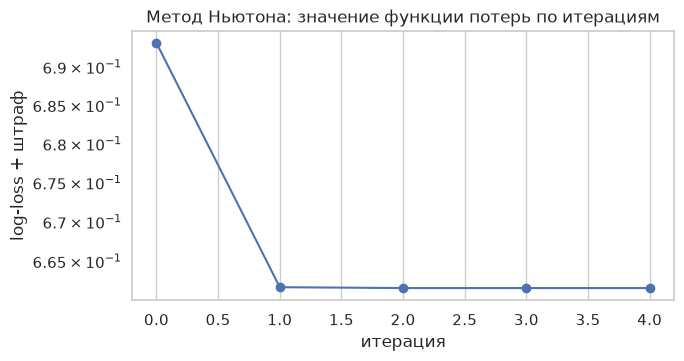

In [16]:
sk_coef = baseline_cls.coef_[0]
my_coef = custom_cls.coef_
print(f"Макс. |разность коэффициентов| логистической регрессии: {np.max(np.abs(sk_coef - my_coef)):.2e}")
print(f"Макс. |разность предсказаний| линейной регрессии: "
      f"{np.max(np.abs(baseline_reg.predict(X_reg_test) - custom_reg.predict(X_reg_test))):.2e}")
ax = pd.Series(custom_cls.loss_curve_).plot(marker="o", figsize=(7, 3.5), logy=True,
                                           title="Метод Ньютона: значение функции потерь по итерациям")
ax.set_xlabel("итерация")
ax.set_ylabel("log-loss + штраф")
print("Итераций Ньютона:", len(custom_cls.loss_curve_) - 1)

<!-- lab2_custom -->
**Вывод по собственной реализации.**
* Метрики собственных моделей **совпадают** с `sklearn` (ROC-AUC 0.6342, R² 0.6420; accuracy отличается на 2 объекта из 10 294).
* Линейная регрессия совпадает с `sklearn` с машинной точностью (≈1e-14): обе решают одну и ту же задачу МНК через псевдообратную матрицу.
* Коэффициенты логистической регрессии отличаются до 0.013: на немасштабированных данных `lbfgs` в `sklearn` останавливается по критерию `tol` раньше точного оптимума, а метод Ньютона сходится за 4 итерации до точности 1e-6 (квадратичная сходимость, см. график). На предсказания это не влияет.
* Собственная логистическая регрессия на сырых данных обучается в ≈14 раз быстрее `sklearn` (2.1 с против 29.5 с): метод Ньютона не чувствителен к масштабу признаков, т. к. гессиан учитывает кривизну функции потерь по каждому направлению.

### 4.2. Собственная реализация + техники улучшенного бейзлайна

Подставляем собственные модели в конвейеры улучшенного бейзлайна с теми же признаками и подобранными гиперпараметрами. Соответствие параметров: `l1_ratio=0` в `sklearn` ↔ `penalty="l2"` в собственной реализации, `l1_ratio=1` ↔ `penalty="l1"`; `Ridge(alpha)` ↔ `LinearRegression(alpha)`.

In [17]:
best_cls = search_cls.best_params_
best_reg = search_reg.best_params_

custom_improved_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", drop_constant=True, synergy=True)),
    ("scaler", StandardScaler()),
    ("model", mllab.LogisticRegression(C=best_cls["model__C"],
                                       penalty="l1" if best_cls["model__l1_ratio"] == 1.0 else "l2",
                                       max_iter=1000)),
], memory=memory)
custom_improved_reg = Pipeline([
    ("features", ChessFeatures(interactions=True)),
    ("model", mllab.ClippedRegressor(mllab.LinearRegression(alpha=best_reg["model__estimator__alpha"]))),
])

log.add("classification", "custom improved",
        evaluate(custom_improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom improved",
        evaluate(custom_improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn improved", "custom improved"]],
        log.table("regression").loc[["sklearn improved", "custom improved"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn improved,0.6395,0.5988,0.6392,1.3509,0.1814
custom improved,0.6395,0.5986,0.6392,3.6558,0.1505


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn improved,0.9206,0.1407,0.0816,0.3741,0.0445
custom improved,0.9206,0.1407,0.0816,1.4441,0.0174


<!-- lab2_custom_improved -->
**Вывод.** С техниками улучшенного бейзлайна собственные модели дают **те же метрики**, что и `sklearn` (ROC-AUC 0.6395, R² 0.9206), и так же улучшаются относительно своего бейзлайна (п. 4.1): +0.005 ROC-AUC и +0.28 R². На стандартизованных данных `lbfgs` уже сходится быстро, и `sklearn` обучается быстрее (1.4 с против 3.7 с): каждая итерация Ньютона формирует гессиан по всей выборке (n·d²), а с ростом числа признаков (741 у регрессии) решение системы d×d тоже дорожает.

## 5. Итоги лабораторной работы

Сводная таблица всех вариантов; результаты сохраняются в `results/lab2.json`.

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6342,0.5979,0.6399,29.5438,0.0419
sklearn improved,0.6395,0.5988,0.6392,1.3509,0.1814
custom,0.6342,0.5977,0.6399,2.0971,0.0488
custom improved,0.6395,0.5986,0.6392,3.6558,0.1505


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6420,0.2989,0.2583,0.1220,0.0129
sklearn improved,0.9206,0.1407,0.0816,0.3741,0.0445
custom,0.6420,0.2989,0.2583,0.0724,0.0030
custom improved,0.9206,0.1407,0.0816,1.4441,0.0174


Сохранено: results/lab2.json


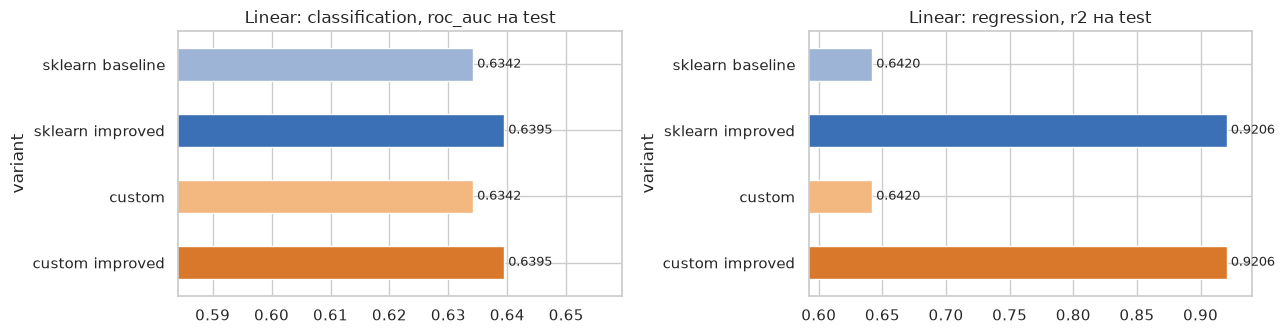

In [18]:
display(log.table("classification"), log.table("regression"))
log.plot()
print("Сохранено:", log.save().relative_to(ROOT))

<!-- lab2_summary -->
**Выводы по ЛР №2.**
1. Логистическая регрессия — сильный бейзлайн для Dota 2 (ROC-AUC 0.634 без какой-либо настройки): данные хорошо описываются аддитивной моделью «сумма сил героев».
2. Для классификации главную пользу дали признаки синергии и контрпиков (+0.005 ROC-AUC) и стандартизация (ускорение в десятки раз); обработка мета-признаков и подбор регуляризации почти ничего не дают.
3. Для регрессии линейная модель без доработок слаба (R² 0.64), но попарные взаимодействия, Ridge-регуляризация и обрезка предсказаний поднимают R² до 0.92.
4. Собственные реализации (аналитическое решение МНК/Ridge, метод Ньютона для логистической регрессии) воспроизводят результаты `sklearn` точно; метод Ньютона сходится за единицы итераций и нечувствителен к масштабу признаков.